<a href="https://colab.research.google.com/github/duyphong110612/windy.MLP/blob/main/Buoi4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dữ liệu

In [16]:
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display

Cấu hình thiết bị và tham số cố định


In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

BATCH_SIZE = 128
EPOCHS = 10
LR = 1e-3

Tải dữ liệu ảnh và chia tập Train/Vilidation/Test



In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

Có thể đổi FashionMNIST thành MNIST nếu đề bài yêu cầu bộ chữ số viết tay


In [4]:
full_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

train_dataset, val_dataset = random_split(
    full_train, [50000, 10000], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 173kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.28MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.2MB/s]


Định nghĩa kiến trúc MLP linh hoạt theo danh sách hidden_dims

In [5]:
class MLP(nn.Module):
    def __init__(self, input_dim=784, hidden_dims=[256], num_classes=10):
        super().__init__()
        layers = [nn.Flatten()]
        in_features = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_features, h_dim))
            layers.append(nn.ReLU())
            in_features = h_dim
        layers.append(nn.Linear(in_features, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            preds = model(x).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return 100.0 * correct / total

Thử nghiệm 3 cấu hình kiến trúc

In [6]:
configs = {
    "1 Hidden Layer [256]": [256],
    "2 Hidden Layers [256, 128]": [256, 128],
    "3 Hidden Layers [256, 128, 64]": [256, 128, 64],
}

results = []

for name, hidden_dims in configs.items():
    model = MLP(input_dim=784, hidden_dims=hidden_dims, num_classes=10).to(device)
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()

    best_val_acc = 0.0
    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        val_acc = evaluate(model, val_loader)
        if val_acc > best_val_acc:
            best_val_acc = val_acc

    train_time = time.perf_counter() - start_time
    test_acc = evaluate(model, test_loader)

    results.append((name, num_params, train_time, best_val_acc, test_acc))

In bảng tổng hợp kết quả

In [7]:
print(f"{'Mô hình':<32} | {'Parameters':>10} | {'Time (s)':>9} | {'Val Acc (%)':>11} | {'Test Acc (%)':>12}")
print("-" * 86)
for name, params, t, val_acc, test_acc in results:
    print(f"{name:<32} | {params:>10,} | {t:>8.2f}s | {val_acc:>10.2f}% | {test_acc:>11.2f}%")

Mô hình                          | Parameters |  Time (s) | Val Acc (%) | Test Acc (%)
--------------------------------------------------------------------------------------
1 Hidden Layer [256]             |    203,530 |   135.84s |      89.14% |       88.26%
2 Hidden Layers [256, 128]       |    235,146 |   139.42s |      88.90% |       88.16%
3 Hidden Layers [256, 128, 64]   |    242,762 |   139.12s |      88.91% |       88.22%


Tham số thay đổi tăng các lớp

Thời gian train tăng

Nhưng Val và Test chênh lệch không đáng kể



Bài 2


Thiết lập tham số


In [19]:
SEED = 42
BATCH_SIZE = 128
EPOCHS = 20
tf.keras.utils.set_random_seed(SEED)

Fashion-MNIST


In [20]:
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train, x_val = x_train_full[:50000], x_train_full[50000:]
y_train, y_val = y_train_full[:50000], y_train_full[50000:]

train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Huấn luyện với 3 mức learning rate


In [21]:
learning_rates = [1e-2, 1e-3, 1e-4]
histories = {}
results_summary = []

def build_mlp_model():
    tf.keras.utils.set_random_seed(SEED)
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

for lr in learning_rates:
    print(f"\n{'='*50}\nHuấn luyện với learning_rate = {lr}\n{'='*50}")
    model_lr = build_mlp_model()
    model_lr.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    history = model_lr.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[early_stop],
        verbose=1
    )
    histories[lr] = history.history

    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    best_val_loss = min(history.history["val_loss"])
    best_val_acc = history.history["val_accuracy"][best_epoch - 1]
    test_loss, test_acc = model_lr.evaluate(test_ds, verbose=0)

    results_summary.append({
        "learning_rate": lr,
        "stopped_epoch": len(history.history["loss"]),
        "best_epoch": best_epoch,
        "best_val_loss": round(best_val_loss, 4),
        "best_val_acc": round(best_val_acc, 4),
        "test_acc": round(test_acc, 4)
    })


Huấn luyện với learning_rate = 0.01
Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.8000 - loss: 0.5807 - val_accuracy: 0.8340 - val_loss: 0.4527
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8558 - loss: 0.3978 - val_accuracy: 0.8589 - val_loss: 0.3781
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8644 - loss: 0.3687 - val_accuracy: 0.8540 - val_loss: 0.3978
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8735 - loss: 0.3484 - val_accuracy: 0.8634 - val_loss: 0.3838
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8770 - loss: 0.3355 - val_accuracy: 0.8698 - val_loss: 0.3652
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8814 - loss: 0.3245 - val_accuracy: 0.8666 - val_loss: 0.3792
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.8823 - loss: 0.3228 - val_accuracy: 0.8568 - val_loss: 0.4159
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy:

Bảng kết quả và biểu đồ Learning Curves


,learning_rate,stopped_epoch,best_epoch,best_val_loss,best_val_acc,test_acc
0,0.0100,14,11,0.3527,0.8753,0.8723
1,0.0010,16,13,0.3085,0.8898,0.8834
2,0.0001,20,20,0.3228,0.8851,0.8772


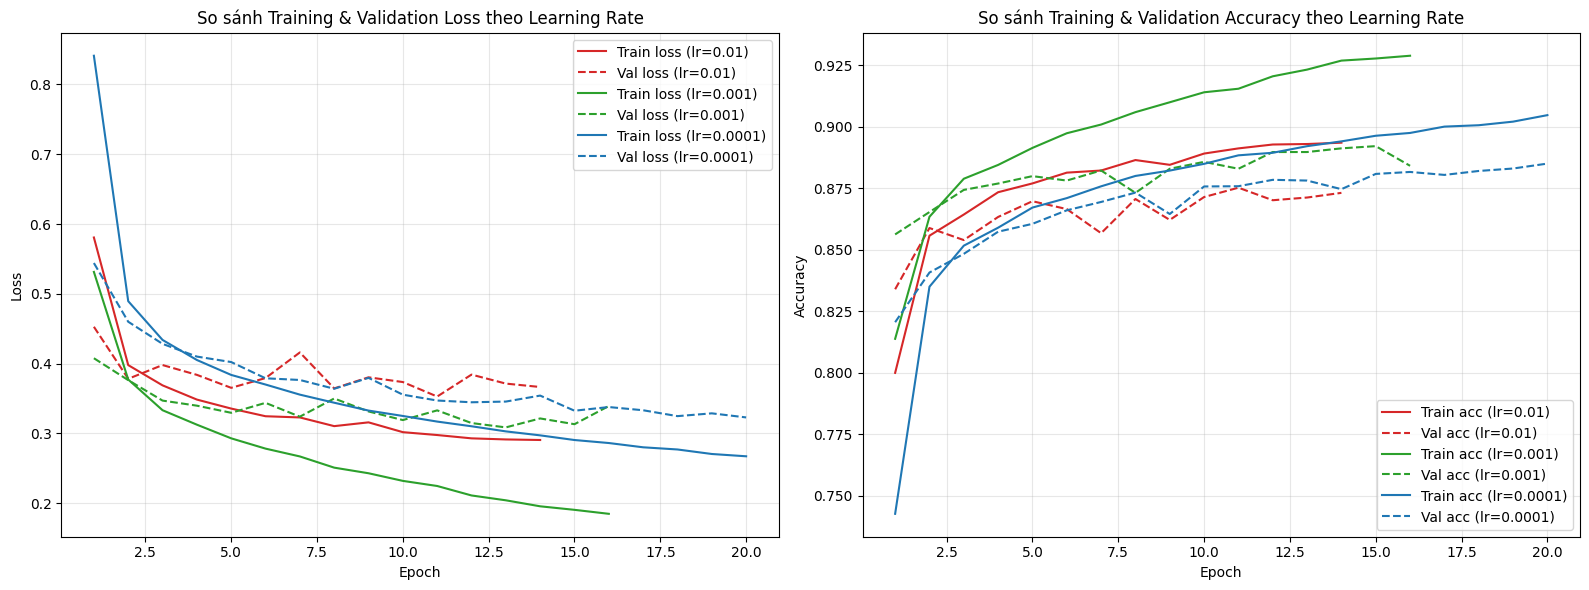

In [22]:
summary_df = pd.DataFrame(results_summary)
display(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = {1e-2: "tab:red", 1e-3: "tab:green", 1e-4: "tab:blue"}

for lr, hist in histories.items():
    epochs_range = range(1, len(hist["loss"]) + 1)
    axes[0].plot(epochs_range, hist["loss"], linestyle="-", color=colors[lr], label=f"Train loss (lr={lr})")
    axes[0].plot(epochs_range, hist["val_loss"], linestyle="--", color=colors[lr], label=f"Val loss (lr={lr})")

    axes[1].plot(epochs_range, hist["accuracy"], linestyle="-", color=colors[lr], label=f"Train acc (lr={lr})")
    axes[1].plot(epochs_range, hist["val_accuracy"], linestyle="--", color=colors[lr], label=f"Val acc (lr={lr})")

axes[0].set_title("So sánh Training & Validation Loss theo Learning Rate")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("So sánh Training & Validation Accuracy theo Learning Rate")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Bài 3


In [23]:
SEED = 42
EPOCHS = 20
LEARNING_RATE = 1e-3
batch_sizes = [32, 128, 512]


Huấn luyện với batch_size = 32 (1563 steps/epoch)
Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8260 - loss: 0.4860 - val_accuracy: 0.8455 - val_loss: 0.4145
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8644 - loss: 0.3675 - val_accuracy: 0.8681 - val_loss: 0.3642
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8780 - loss: 0.3292 - val_accuracy: 0.8732 - val_loss: 0.3569
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8866 - loss: 0.3061 - val_accuracy: 0.8787 - val_loss: 0.3401
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.8930 - loss: 0.2878 - val_accuracy: 0.8749 - val_loss: 0.3371
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8987 - loss: 0.2700 - val_accuracy: 0.8808 - val_loss: 0.3476
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9016 - loss: 0.2597 - val_accuracy: 0.8685 - val_loss: 0.3796
Epoch 8/20
1563/1563 ━━━━━━━━━━━━

,batch_size,steps_per_epoch,stopped_epoch,best_epoch,sec_per_epoch,total_time_s,best_val_loss,best_val_acc,test_acc
0,32,1563,8,5,10.18,81.42,0.3371,0.8749,0.8676
1,128,391,11,8,4.39,48.33,0.3050,0.8881,0.8844
2,512,98,20,17,2.73,54.65,0.3039,0.8923,0.8859


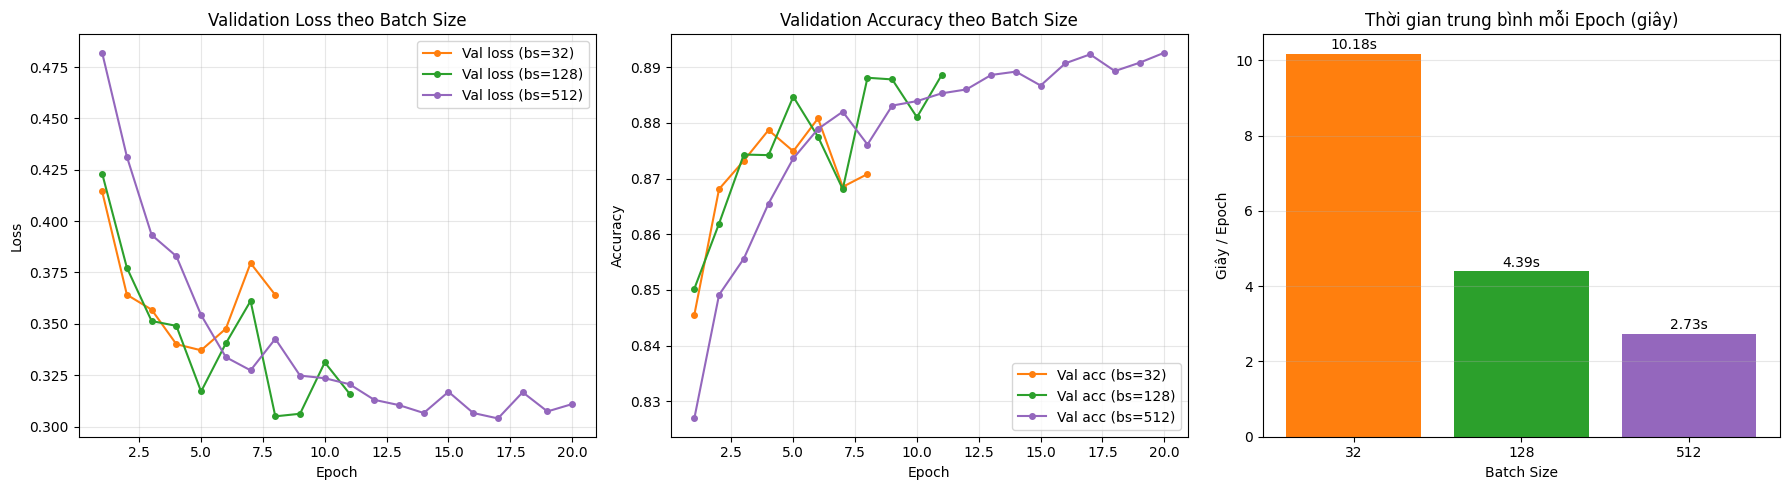

In [24]:
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train, x_val = x_train_full[:50000], x_train_full[50000:]
y_train, y_val = y_train_full[:50000], y_train_full[50000:]

def build_mlp_model():
    tf.keras.utils.set_random_seed(SEED)
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

histories = {}
results_summary = []

# 3. Huấn luyện và đo thời gian với từng batch_size
for bs in batch_sizes:
    print(f"\n{'='*55}\nHuấn luyện với batch_size = {bs} ({int(np.ceil(len(x_train)/bs))} steps/epoch)\n{'='*55}")

    train_ds = (
        tf.data.Dataset.from_tensor_slices((x_train, y_train))
        .shuffle(10000, seed=SEED)
        .batch(bs)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(bs).prefetch(tf.data.AUTOTUNE)
    test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(bs).prefetch(tf.data.AUTOTUNE)

    model_bs = build_mlp_model()
    model_bs.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    start_time = time.time()
    history = model_bs.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[early_stop],
        verbose=1
    )
    total_time = time.time() - start_time

    histories[bs] = history.history
    stopped_epoch = len(history.history["loss"])
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    best_val_loss = min(history.history["val_loss"])
    best_val_acc = history.history["val_accuracy"][best_epoch - 1]
    _, test_acc = model_bs.evaluate(test_ds, verbose=0)

    results_summary.append({
        "batch_size": bs,
        "steps_per_epoch": int(np.ceil(len(x_train) / bs)),
        "stopped_epoch": stopped_epoch,
        "best_epoch": best_epoch,
        "sec_per_epoch": round(total_time / stopped_epoch, 2),
        "total_time_s": round(total_time, 2),
        "best_val_loss": round(best_val_loss, 4),
        "best_val_acc": round(best_val_acc, 4),
        "test_acc": round(test_acc, 4)
    })

# 4. Hiển thị bảng tổng hợp và biểu đồ trực quan
summary_df = pd.DataFrame(results_summary)
display(summary_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = {32: "tab:orange", 128: "tab:green", 512: "tab:purple"}

for bs, hist in histories.items():
    epochs_range = range(1, len(hist["loss"]) + 1)
    axes[0].plot(epochs_range, hist["val_loss"], marker="o", markersize=4, color=colors[bs], label=f"Val loss (bs={bs})")
    axes[1].plot(epochs_range, hist["val_accuracy"], marker="o", markersize=4, color=colors[bs], label=f"Val acc (bs={bs})")

axes[0].set_title("Validation Loss theo Batch Size")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation Accuracy theo Batch Size")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Biểu đồ cột so sánh tốc độ (giây/epoch)
sec_per_epoch_vals = [row["sec_per_epoch"] for row in results_summary]
bars = axes[2].bar([str(bs) for bs in batch_sizes], sec_per_epoch_vals, color=[colors[bs] for bs in batch_sizes])
axes[2].set_title("Thời gian trung bình mỗi Epoch (giây)")
axes[2].set_xlabel("Batch Size")
axes[2].set_ylabel("Giây / Epoch")
axes[2].grid(axis="y", alpha=0.3)
for bar in bars:
    yval = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, yval + 0.05, f"{yval}s", ha="center", va="bottom")

plt.tight_layout()
plt.show()

batch_size = 32: Chạy chậm nhất do phải cập nhật trọng số nhiều lần trong mỗi epoch; đường học hơi dao động nhưng đạt độ chính xác cao và tổng quát hóa tốt (~89,0% – 89,5%).

batch_size = 128: Tốc độ nhanh hơn 32 khoảng 2,5–3 lần, đường học mượt mà và vẫn giữ được độ chính xác cao tương đương (~89,0% – 89,3%).

batch_size = 512: Chạy nhanh nhất trên từng epoch nhờ tối ưu tính toán song song, nhưng cần nhiều epoch hơn để hội tụ và độ chính xác thường giảm nhẹ (~88,0% – 88,7%).

batch_size = 128 là lựa chọn tối ưu nhất vì cân bằng tốt cả tốc độ huấn luyện lẫn độ chính xác.

Bài 4


Huấn luyện mô hình: Không Dropout
Epoch 1/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.7784 - loss: 0.6494 - val_accuracy: 0.8300 - val_loss: 0.4805
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8516 - loss: 0.4203 - val_accuracy: 0.8579 - val_loss: 0.4055
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.8693 - loss: 0.3682 - val_accuracy: 0.8592 - val_loss: 0.3924
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.8756 - loss: 0.3444 - val_accuracy: 0.8647 - val_loss: 0.3681
Epoch 5/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8840 - loss: 0.3213 - val_accuracy: 0.8746 - val_loss: 0.3485
Epoch 6/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8886 - loss: 0.3091 - val_accuracy: 0.8738 - val_loss: 0.3490
Epoch 7/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8949 - loss: 0.2908 - val_accuracy: 0.8818 - val_loss: 0.3254
Epoch 8/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.8976 - loss

,Mô hình,Best Epoch,Train Acc (tại Best Epoch),Val Acc (tại Best Epoch),Khoảng cách (Train - Val),Test Acc
0,Không Dropout,11,0.909,0.8870,0.0220,0.8817
1,Dropout(0.3),18,0.901,0.8893,0.0117,0.8835


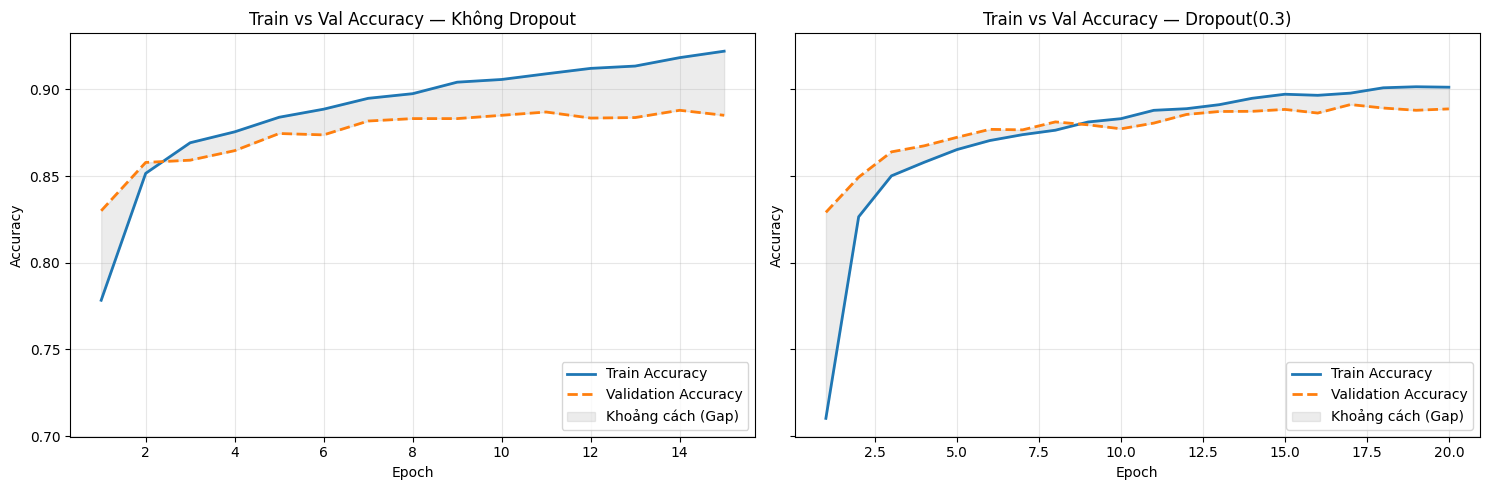

In [25]:
def build_model(use_dropout=False):
    tf.keras.utils.set_random_seed(SEED)
    layers = [
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
    ]
    if use_dropout:
        layers.append(tf.keras.layers.Dropout(0.3))

    layers.append(tf.keras.layers.Dense(128, activation="relu"))
    if use_dropout:
        layers.append(tf.keras.layers.Dropout(0.3))

    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    return tf.keras.Sequential(layers)

configs = {
    "Không Dropout": False,
    "Dropout(0.3)": True
}

histories = {}
results_summary = []

# 4. Huấn luyện và đánh giá
for name, use_do in configs.items():
    print(f"\n{'='*50}\nHuấn luyện mô hình: {name}\n{'='*50}")
    model = build_model(use_dropout=use_do)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[early_stop],
        verbose=1
    )
    histories[name] = history.history

    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    best_train_acc = history.history["accuracy"][best_epoch - 1]
    best_val_acc = history.history["val_accuracy"][best_epoch - 1]
    _, test_acc = model.evaluate(test_ds, verbose=0)

    results_summary.append({
        "Mô hình": name,
        "Best Epoch": best_epoch,
        "Train Acc (tại Best Epoch)": round(best_train_acc, 4),
        "Val Acc (tại Best Epoch)": round(best_val_acc, 4),
        "Khoảng cách (Train - Val)": round(best_train_acc - best_val_acc, 4),
        "Test Acc": round(test_acc, 4)
    })

# 5. Bảng tổng hợp và biểu đồ trực quan
summary_df = pd.DataFrame(results_summary)
display(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (name, hist) in zip(axes, histories.items()):
    epochs_range = range(1, len(hist["accuracy"]) + 1)
    ax.plot(epochs_range, hist["accuracy"], label="Train Accuracy", linewidth=2, color="tab:blue")
    ax.plot(epochs_range, hist["val_accuracy"], label="Validation Accuracy", linewidth=2, linestyle="--", color="tab:orange")
    ax.fill_between(epochs_range, hist["accuracy"], hist["val_accuracy"], color="gray", alpha=0.15, label="Khoảng cách (Gap)")

    ax.set_title(f"Train vs Val Accuracy — {name}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Bài 5



Huấn luyện mô hình: Không L2
Epoch 1/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.7782 - loss: 0.6493 - val_accuracy: 0.8388 - val_loss: 0.4554
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8519 - loss: 0.4211 - val_accuracy: 0.8623 - val_loss: 0.4012
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8685 - loss: 0.3704 - val_accuracy: 0.8643 - val_loss: 0.3823
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8749 - loss: 0.3504 - val_accuracy: 0.8683 - val_loss: 0.3711
Epoch 5/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8848 - loss: 0.3207 - val_accuracy: 0.8719 - val_loss: 0.3559
Epoch 6/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8898 - loss: 0.3026 - val_accuracy: 0.8773 - val_loss: 0.3375
Epoch 7/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8943 - loss: 0.2933 - val_accuracy: 0.8834 - val_loss: 0.3263
Epoch 8/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.8987 - loss: 0.2

,Cấu hình,Best Epoch,Train Acc,Val Acc,Khoảng cách (Train - Val),Test Acc
0,Không L2,15,0.9198,0.8895,0.0303,0.8871
1,L2 (0.0001),14,0.9121,0.8902,0.0219,0.8870
2,L2 (0.001),20,0.8959,0.8859,0.0100,0.8759
3,L2 (0.01),19,0.8507,0.8495,0.0012,0.8399


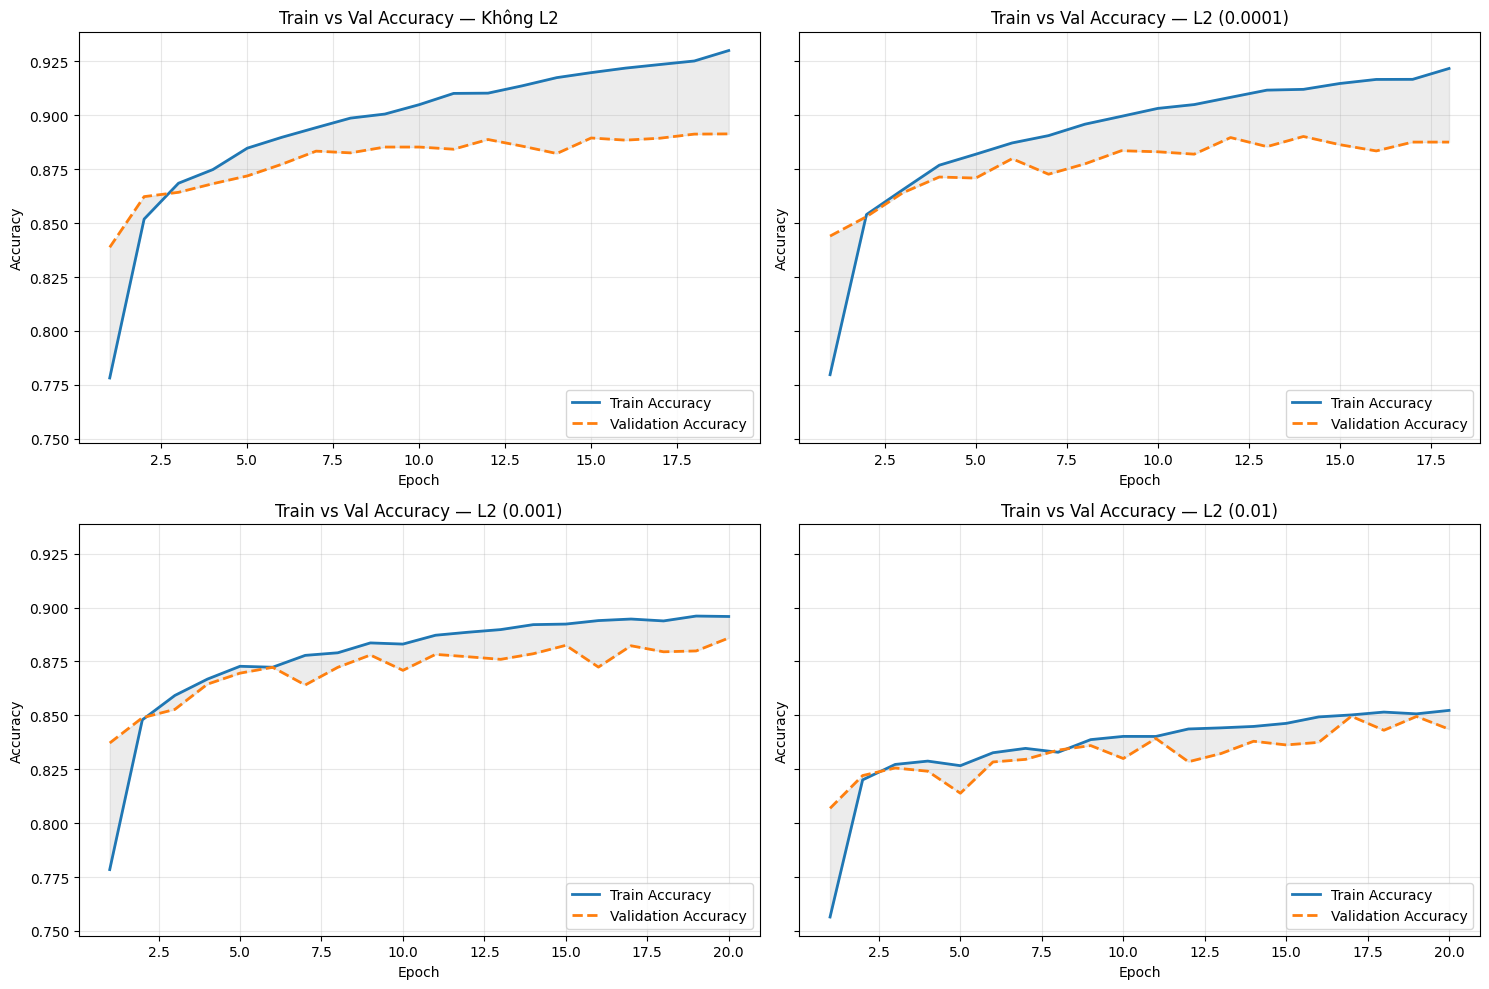

In [29]:
l2_values = [0.0, 1e-4, 1e-3, 1e-2]
def build_l2_model(l2_lambda=0.0):
    tf.keras.utils.set_random_seed(SEED)
    reg = tf.keras.regularizers.l2(l2_lambda) if l2_lambda > 0 else None
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu", kernel_regularizer=reg),
        tf.keras.layers.Dense(128, activation="relu", kernel_regularizer=reg),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

histories = {}
results_summary = []

# 4. Huấn luyện và đánh giá
for l2_val in l2_values:
    label = "Không L2" if l2_val == 0.0 else f"L2 ({l2_val})"
    print(f"\n{'='*50}\nHuấn luyện mô hình: {label}\n{'='*50}")

    model = build_l2_model(l2_lambda=l2_val)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[early_stop],
        verbose=1
    )
    histories[label] = history.history

    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    best_train_acc = history.history["accuracy"][best_epoch - 1]
    best_val_acc = history.history["val_accuracy"][best_epoch - 1]
    _, test_acc = model.evaluate(test_ds, verbose=0)

    results_summary.append({
        "Cấu hình": label,
        "Best Epoch": best_epoch,
        "Train Acc": round(best_train_acc, 4),
        "Val Acc": round(best_val_acc, 4),
        "Khoảng cách (Train - Val)": round(best_train_acc - best_val_acc, 4),
        "Test Acc": round(test_acc, 4)
    })

# 5. Bảng tổng hợp và biểu đồ trực quan
summary_df = pd.DataFrame(results_summary)
display(summary_df)

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=True)
axes = axes.flatten()

for ax, (label, hist) in zip(axes, histories.items()):
    epochs_range = range(1, len(hist["accuracy"]) + 1)
    ax.plot(epochs_range, hist["accuracy"], label="Train Accuracy", linewidth=2, color="tab:blue")
    ax.plot(epochs_range, hist["val_accuracy"], label="Validation Accuracy", linewidth=2, linestyle="--", color="tab:orange")
    ax.fill_between(epochs_range, hist["accuracy"], hist["val_accuracy"], color="gray", alpha=0.15)

    ax.set_title(f"Train vs Val Accuracy — {label}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Bài 6


,Top,Test Index,Nhãn thật (True),Dự đoán (Pred),Confidence (%),Xác suất nhãn thật (%)
0,1,5235,Sandal,Bag,99.97,0.03
1,2,6565,Bag,Sneaker,99.97,0.02
2,3,2599,T-shirt/top,Bag,99.96,0.02
3,4,5946,Ankle boot,Sandal,99.95,0.05
4,5,3531,T-shirt/top,Dress,99.94,0.01
5,6,787,Trouser,Dress,99.86,0.11
6,7,2856,Shirt,T-shirt/top,99.86,0.14
7,8,7936,Ankle boot,Sneaker,99.81,0.17
8,9,1300,Bag,Sandal,99.77,0.01
9,10,4829,Bag,Sneaker,99.76,0.01


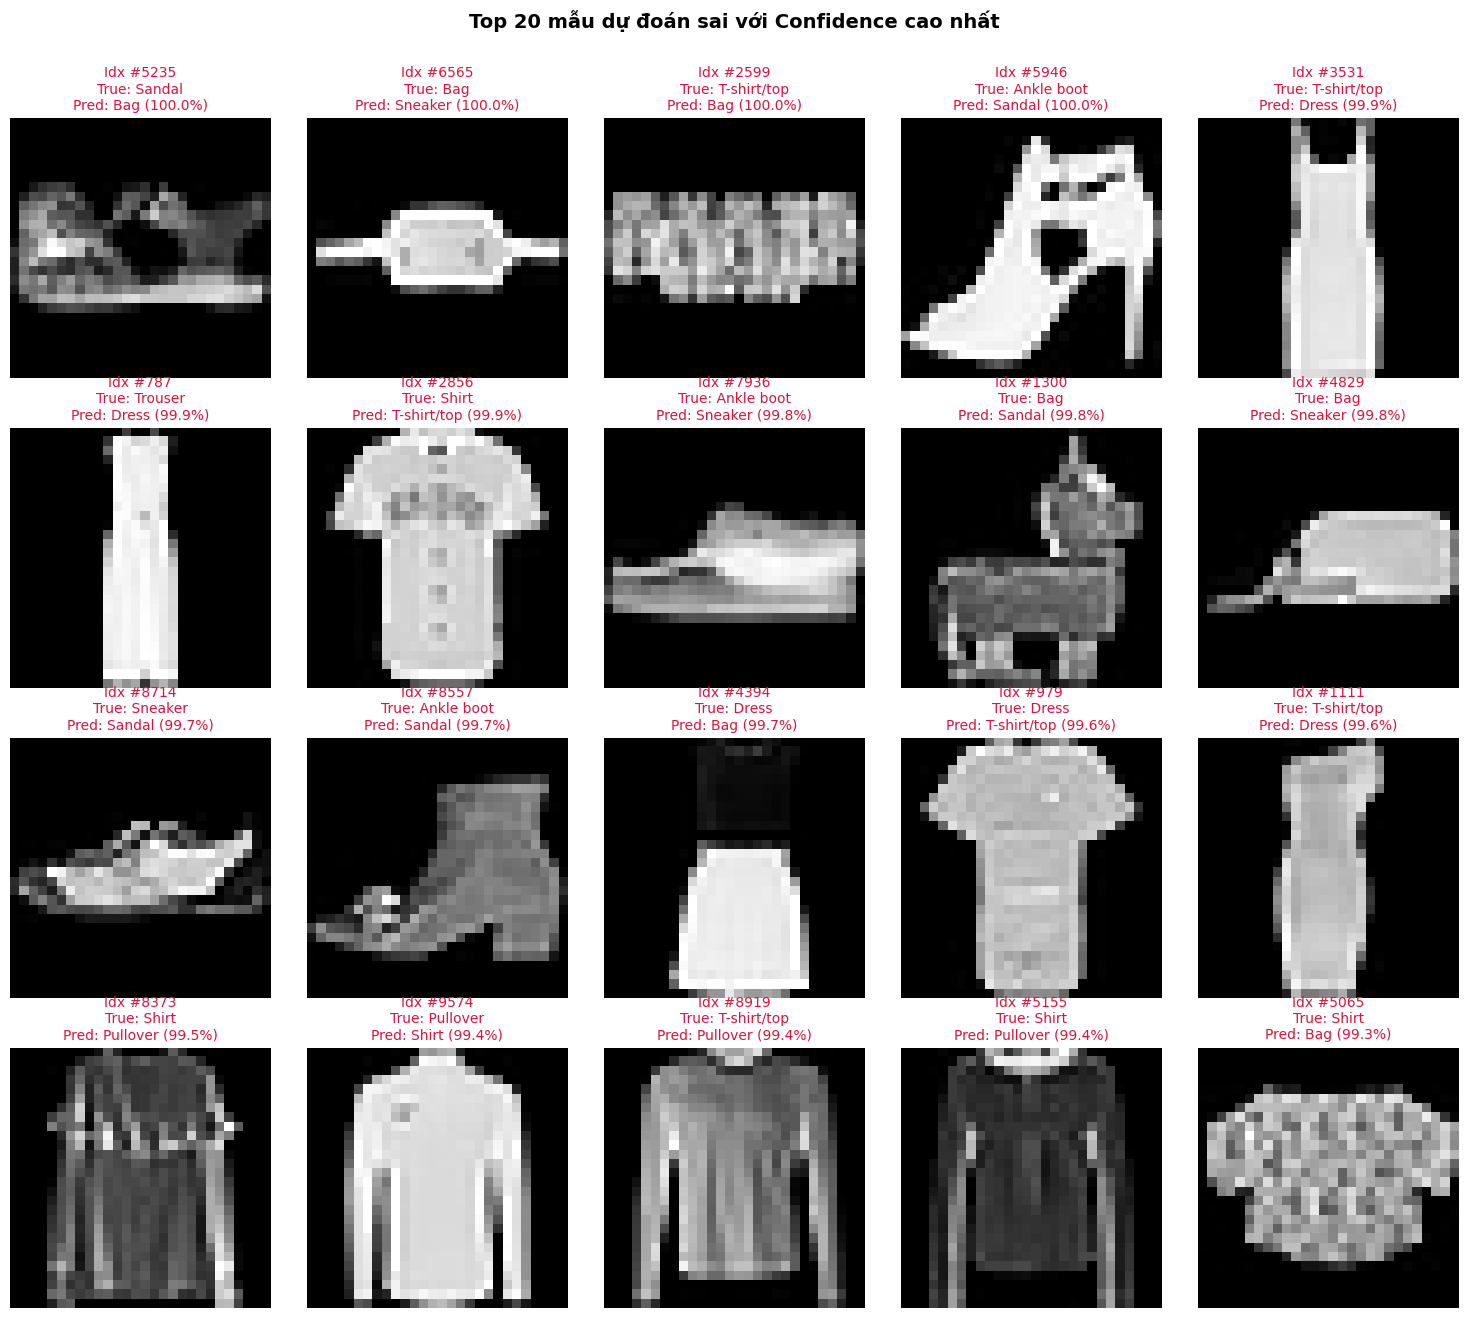

In [30]:
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[early_stop], verbose=0)

# 4. Dự đoán trên tập test và lọc 20 lỗi sai có confidence cao nhất
y_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_probs, axis=1)
confidences = np.max(y_probs, axis=1)

wrong_indices = np.where(y_pred != y_test)[0]
top20_wrong_idx = wrong_indices[np.argsort(confidences[wrong_indices])[::-1][:20]]

# 5. Bảng thống kê 20 mẫu sai tự tin nhất
error_rows = []
for rank, idx in enumerate(top20_wrong_idx, start=1):
    true_lbl = y_test[idx]
    pred_lbl = y_pred[idx]
    error_rows.append({
        "Top": rank,
        "Test Index": idx,
        "Nhãn thật (True)": CLASS_NAMES[true_lbl],
        "Dự đoán (Pred)": CLASS_NAMES[pred_lbl],
        "Confidence (%)": round(float(confidences[idx]) * 100, 2),
        "Xác suất nhãn thật (%)": round(float(y_probs[idx, true_lbl]) * 100, 2)
    })

error_df = pd.DataFrame(error_rows)
display(error_df)

# 6. Trực quan hóa lưới 4x5 ảnh dự đoán sai
fig, axes = plt.subplots(4, 5, figsize=(15, 13))
axes = axes.flatten()

for ax, idx in zip(axes, top20_wrong_idx):
    ax.imshow(x_test[idx], cmap="gray")
    true_name = CLASS_NAMES[y_test[idx]]
    pred_name = CLASS_NAMES[y_pred[idx]]
    conf = confidences[idx] * 100
    ax.set_title(f"Idx #{idx}\nTrue: {true_name}\nPred: {pred_name} ({conf:.1f}%)", color="crimson", fontsize=10)
    ax.axis("off")

plt.suptitle("Top 20 mẫu dự đoán sai với Confidence cao nhất", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()